# 06 · Preparação de imagens para inferência

**Ementa 06** · O modelo de IA (MobileNetV3-Small / EfficientNet-Lite0 quantizado em TensorFlow Lite, Módulo 4) não "vê" uma retinografia: recebe **um tensor** de forma e escala fixas.
Tudo o que fizemos nos notebooks anteriores converge aqui, no **contrato entre a aquisição (Frente F2) e a inferência (Frente F3)**:

```
captura 12 MP ─▶ qualidade (05) ─▶ FOV e recorte (02) ─▶ redimensionar ─▶ realce (03) ─▶ normalizar ─▶ tensor (1, 224, 224, 3)
```

Neste notebook você vai: **(1)** ver cada etapa e o que ela faz com forma, tipo e memória; **(2)** escolher a interpolação com uma medida; **(3)** comparar realces e normalizações;
**(4)** rodar o **fluxo completo** nas 115 imagens com **orçamento de tempo**; **(5)** entender por que o pré-processamento do treino e da inferência precisam ser **idênticos** — e medir o que acontece quando não são; **(6)** exportar amostras e a configuração.

> ⚠️ **Convenção a confirmar com a Frente F3.** As escalas numéricas abaixo são as usuais dessas famílias de modelos, mas a **entrada real** de cada `.tflite` (tamanho, tipo, escala, `scale`/`zero_point`) deve ser lida no próprio modelo (`interpreter.get_input_details()`) e **igualada ao pipeline de treinamento**.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
import json, time
from PIL import Image
from retina_pdi import fluxo, qualidade as Q, metricas as M

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


In [2]:
man = dados.carregar_manifesto()
# um exemplo de cada condição, de fontes diferentes
ids = ["hrf_08_dr", "rfmid_dmri_03", "odir_glaucoma_04", "hrf_01_h"]
exemplos = {i: dados.carregar_rgb(man.set_index("id").loc[i, "arquivo"]) for i in ids}
for i, im in exemplos.items():
    print(f"{i:18s} {im.shape[1]}×{im.shape[0]}  ({im.nbytes/1e6:.1f} MB)")

hrf_08_dr          3504×2336  (24.6 MB)
rfmid_dmri_03      2144×1424  (9.2 MB)
odir_glaucoma_04   512×512  (0.8 MB)
hrf_01_h           3504×2336  (24.6 MB)


## 1. Etapa por etapa

O que cada passo faz com **forma**, **tipo** e **memória** (e por que o *padding* quadrado importa: redimensionar direto para 224×224 sem ele **distorceria** a proporção da retina):

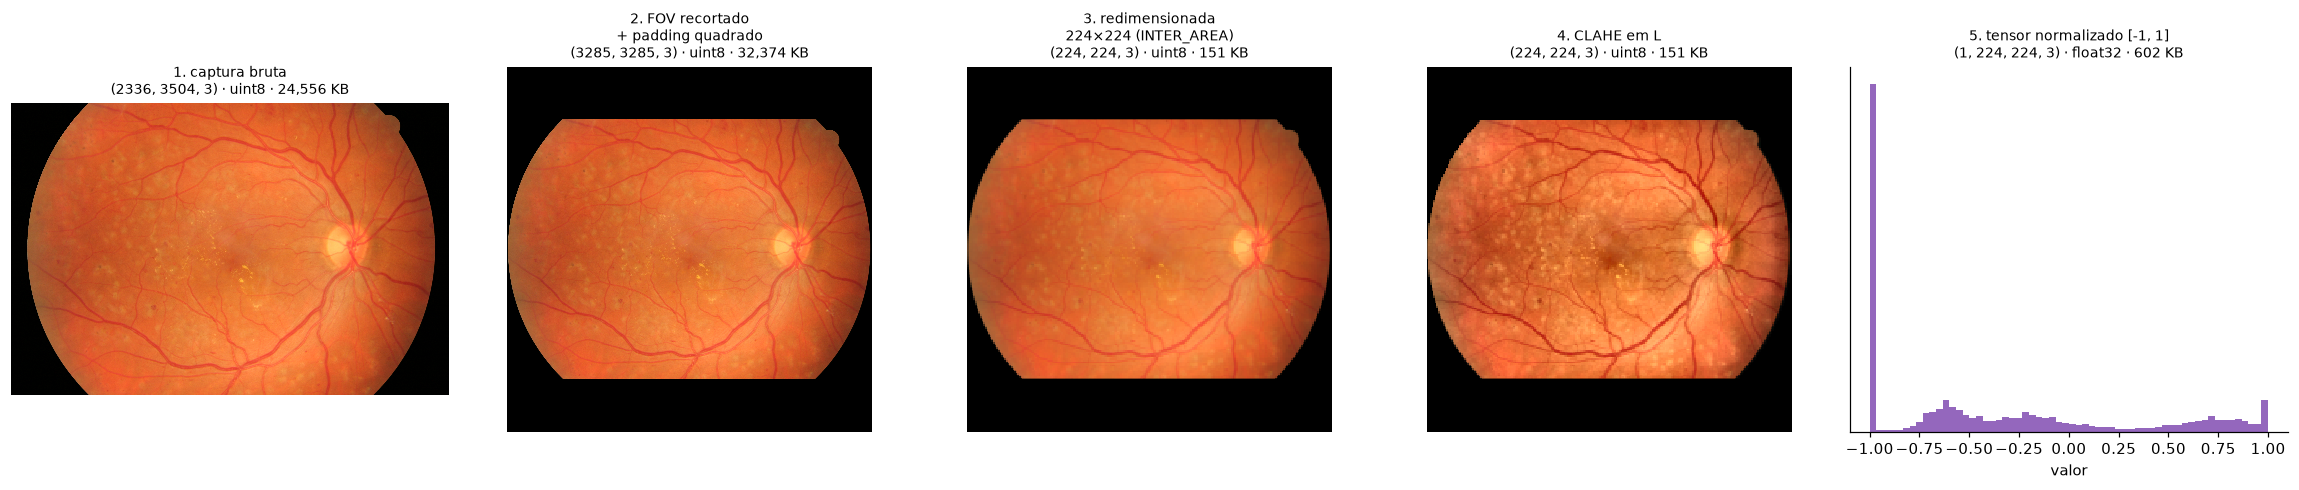

mesmo resultado pela função do pacote: True


In [3]:
im = exemplos["hrf_08_dr"]
fov_ = P.mascara_fov(im)
recortada, m_rec = P.recortar_fov(im, fov_, quadrado=True)
pequena = cv2.resize(recortada, (224, 224), interpolation=cv2.INTER_AREA)
m_peq = cv2.resize(m_rec.astype(np.uint8), (224, 224), interpolation=cv2.INTER_NEAREST).astype(bool)
realcada = P.clahe_lab(pequena); realcada[~m_peq] = 0
tensor = P.normalizar(realcada, "menos1_1")[None]

etapas = [("1. captura bruta", im), ("2. FOV recortado\n+ padding quadrado", recortada), ("3. redimensionada\n224×224 (INTER_AREA)", pequena), ("4. CLAHE em L", realcada)]
fig, axs = plt.subplots(1, 5, figsize=(21, 4.4))
for ax, (t_, x) in zip(axs, etapas):
    ax.imshow(x); ax.set_title(f"{t_}\n{x.shape} · {x.dtype} · {x.nbytes/1e3:,.0f} KB", fontsize=9); ax.axis("off")
axs[4].hist(tensor.ravel(), bins=60, color="tab:purple"); axs[4].set_title(f"5. tensor normalizado [-1, 1]\n{tensor.shape} · {tensor.dtype} · {tensor.nbytes/1e3:,.0f} KB", fontsize=9)
axs[4].set_yticks([]); axs[4].set_xlabel("valor")
fig.tight_layout(); V.salvar_figura(fig, "06_etapas"); plt.show()
print("mesmo resultado pela função do pacote:", np.allclose(tensor, P.preparar_para_inferencia(im, 224, "clahe", "menos1_1", fov=fov_), atol=1e-6))

Repare na **redução de informação**: de ≈ 24 MB (8 MP) para **≈ 150 KB** (224×224×3 em `uint8`) — mais de 150× menos pixels. E o tensor `float32` ocupa 4× mais que o `uint8`: por isso modelos **quantizados** (entrada `uint8`/`int8`) são tão atraentes em dispositivos de borda.

## 2. Interpolação: como reduzir sem perder os vasos

Reduzir de ~1200 px para 224 px joga fora ~ 5× em cada eixo. Métodos que só "amostram" alguns pixels (`NEAREST`, `LINEAR`) sofrem *aliasing*: estruturas finas somem ou viram serrilhado. `INTER_AREA` faz a média de todos os pixels cobertos.
Medimos duas coisas, em 45 imagens: **(a)** o **contraste dos vasos** (Cohen *d*, com o padrão-ouro do HRF reduzido junto) e **(b)** a **fidelidade** (PSNR) em relação à redução por **média de área**, que é o modelo físico de um sensor com fotossítios maiores (notebook 01) — a referência "sem aliasing".

In [4]:
hrf = dados.carregar_hrf(1168)
metodos = {"NEAREST": cv2.INTER_NEAREST, "LINEAR": cv2.INTER_LINEAR, "CUBIC": cv2.INTER_CUBIC, "LANCZOS4": cv2.INTER_LANCZOS4, "AREA": cv2.INTER_AREA}
LARG = 224
linhas = []
for it in hrf:
    h, w = it["rgb"].shape[:2]; alt = round(h * LARG / w)
    v_ = cv2.resize(it["vasos"].astype(np.float32), (LARG, alt), interpolation=cv2.INTER_AREA) >= 0.5
    f_ = cv2.resize(it["fov"].astype(np.uint8), (LARG, alt), interpolation=cv2.INTER_NEAREST).astype(bool)
    f_ = P.erodir_fov(f_, 2)
    ref_area = cv2.resize(it["rgb"][..., 1], (LARG, alt), interpolation=cv2.INTER_AREA).astype(np.float32)
    for nome, flag in metodos.items():
        g_ = cv2.resize(it["rgb"][..., 1], (LARG, alt), interpolation=flag)
        mse = np.mean((g_.astype(np.float32)[f_] - ref_area[f_]) ** 2)
        linhas.append(dict(imagem=it["meta"].id, método=nome, d=M.cohen_d(g_, v_, f_, largura_anel=3, folga=1),
                           PSNR_vs_AREA=10 * np.log10(255 ** 2 / mse) if mse > 0 else np.nan))
interp = pd.DataFrame(linhas)
interp.groupby("método")[["d", "PSNR_vs_AREA"]].mean().round(2).loc[list(metodos)]

,d,PSNR_vs_AREA
método,,
NEAREST,0.54,35.50
LINEAR,0.94,43.89
CUBIC,0.95,42.65
LANCZOS4,0.95,42.73
AREA,0.81,NaN


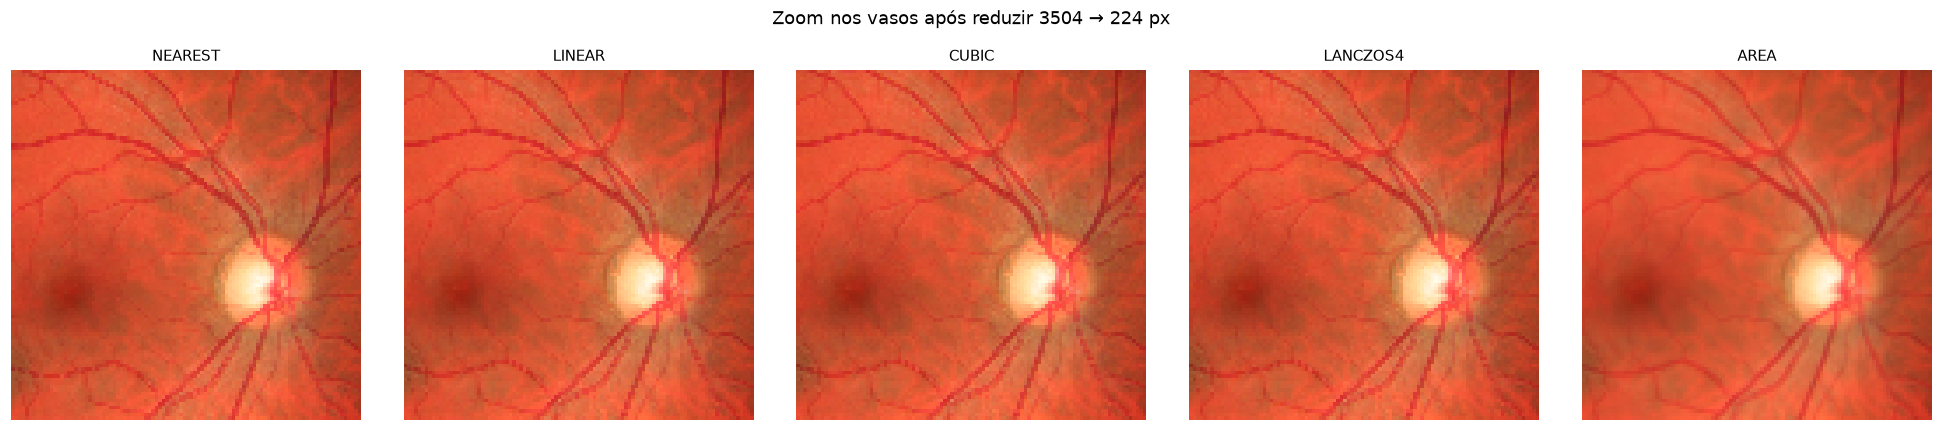

In [5]:
# aspecto visual: recorte de vasos finos, reduzido de 3504 px para 224 px por cada método
grande = dados.carregar_rgb(man.set_index("id").loc["hrf_01_h", "arquivo"])
rec, _ = P.recortar_fov(grande, quadrado=True)
fig, axs = plt.subplots(1, len(metodos), figsize=(3.6 * len(metodos), 3.8))
for ax, (n, flag) in zip(axs, metodos.items()):
    r224 = cv2.resize(rec, (224, 224), interpolation=flag)
    ax.imshow(r224[50:150, 100:200], interpolation="nearest"); ax.set_title(n); ax.axis("off")
fig.suptitle("Zoom nos vasos após reduzir 3504 → 224 px", y=1.02)
fig.tight_layout(); plt.show()

Como ler (números da tabela acima):

* **NEAREST** é o pior nos dois critérios: *d* bem menor (perde vasos) e PSNR mais baixo em relação à redução física.
* **LINEAR, CUBIC e LANCZOS4** mostram *d* **maior** que o da média de área. **Isso não é ganho de informação:** na OpenCV esses métodos usam só uma vizinhança fixa (2×2, 4×4, 8×8 pixels da origem) e **não fazem antialiasing** ao reduzir ≈ 15×; parte dos pixels é ignorada e as bordas ficam mais "duras" (aliasing e *overshoot*), o que **infla** o contraste e o serrilhado (veja o zoom acima) — ainda assim ficam bem próximos da referência (≈ 43 dB).
* **INTER_AREA** integra todos os pixels cobertos — o mesmo que um sensor menor faria — e é a referência do PSNR. É o padrão do pipeline **ao reduzir**; **ao ampliar** (imagens pequenas), `INTER_CUBIC`.

**Lição:** uma métrica só (contraste) pode premiar um artefato. Escolha o método por um critério de **fidelidade**, confirme com a métrica da **tarefa** (exercício 2) e, principalmente, **use o mesmo método no treino e na inferência**.

## 3. Que tamanho de entrada?

O tamanho é definido pelo modelo (224×224 é o usual para MobileNetV3-Small e EfficientNet-Lite0), mas vale ver o compromisso **detalhe × custo** — e lembrar que, se a precisão diagnóstica exigir mais detalhe, o Módulo 4 pode reavaliar (299, 384, 512):

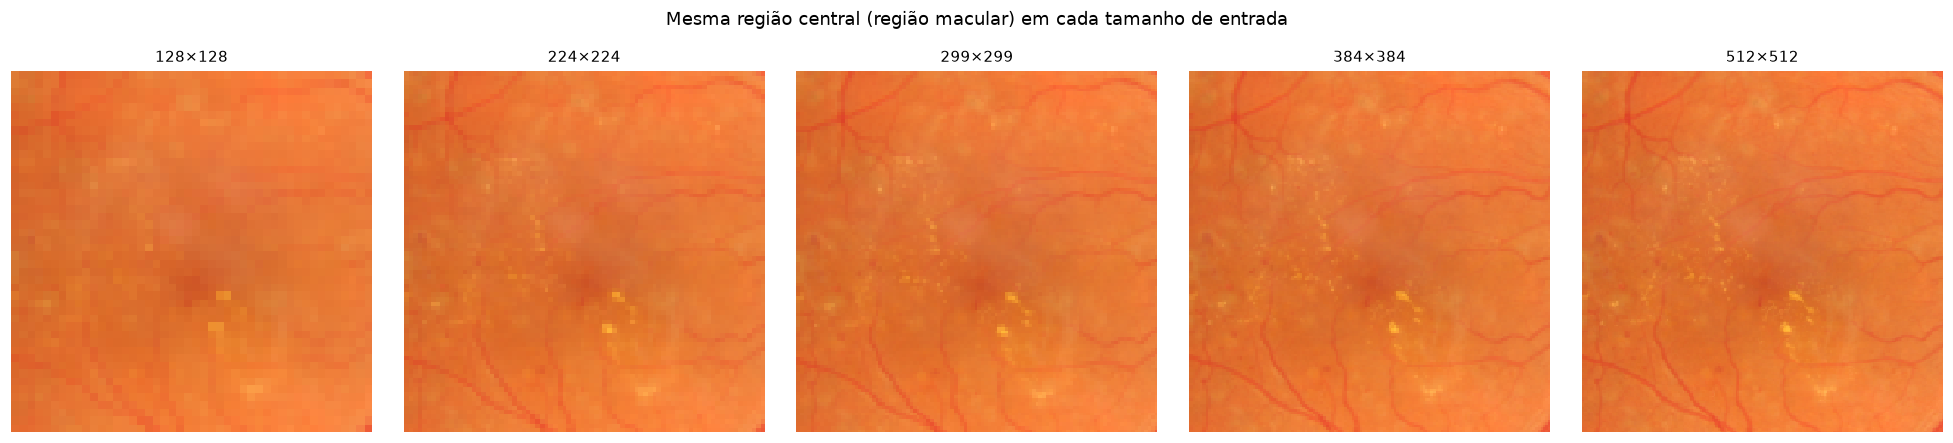

,float32 (KB),uint8 (KB),preparação (ms),px vs 224
tamanho,,,,
128×128,196.6,49.2,153.8,0.3
224×224,602.1,150.5,157.2,1.0
299×299,1072.8,268.2,148.8,1.8
384×384,1769.5,442.4,158.3,2.9
512×512,3145.7,786.4,141.9,5.2


In [6]:
tamanhos = [128, 224, 299, 384, 512]
rec_dr, _ = P.recortar_fov(exemplos["hrf_08_dr"], quadrado=True)
lado0 = rec_dr.shape[0]; c0 = lado0 // 2
fig, axs = plt.subplots(1, len(tamanhos), figsize=(3.6 * len(tamanhos), 3.9))
linhas = []
for ax, t_ in zip(axs, tamanhos):
    r = cv2.resize(rec_dr, (t_, t_), interpolation=cv2.INTER_AREA)
    c, w_ = t_ // 2, int(t_ * 0.18)
    ax.imshow(cv2.resize(r[c - w_:c + w_, c - w_:c + w_], (300, 300), interpolation=cv2.INTER_NEAREST)); ax.set_title(f"{t_}×{t_}"); ax.axis("off")
    t0 = time.perf_counter(); [P.preparar_para_inferencia(exemplos["hrf_08_dr"], t_, "clahe", "menos1_1") for _ in range(3)]; ms = (time.perf_counter() - t0) / 3 * 1e3
    linhas.append({"tamanho": f"{t_}×{t_}", "float32 (KB)": t_ * t_ * 3 * 4 / 1e3, "uint8 (KB)": t_ * t_ * 3 / 1e3, "preparação (ms)": ms, "px vs 224": (t_ / 224) ** 2})
fig.suptitle("Mesma região central (região macular) em cada tamanho de entrada", y=1.02); fig.tight_layout(); plt.show()
pd.DataFrame(linhas).set_index("tamanho").round(1)

O tempo de preparação é quase **constante** (~ 150 ms aqui): domina o recorte do FOV sobre a captura de 8 MP, não o tamanho de saída. Já a memória e o custo do **modelo** crescem com o quadrado do lado.

## 4. Realce na entrada: nenhum, CLAHE ou Ben Graham

O realce aproxima câmeras diferentes e destaca lesões, mas **precisa ser idêntico no treino e na inferência**. Comparamos as três opções (já em 224×224, moldura preta recolocada):

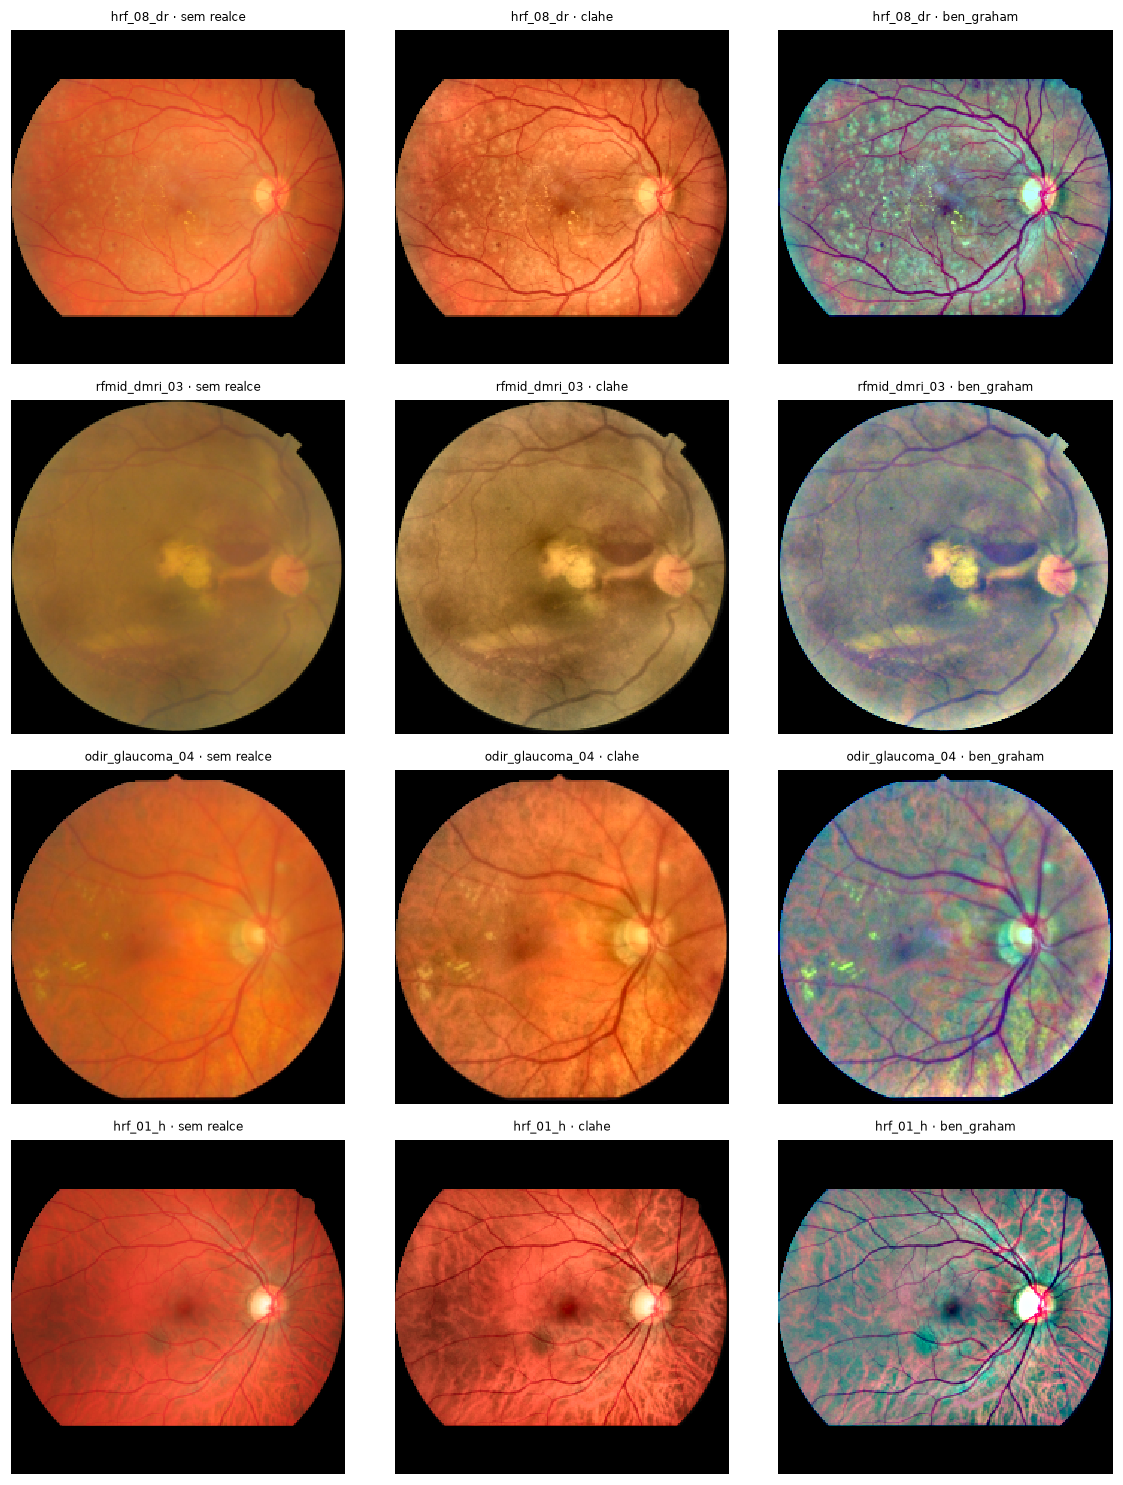

In [7]:
opcoes = [None, "clahe", "ben_graham"]
fig, axs = plt.subplots(len(exemplos), len(opcoes), figsize=(3.6 * len(opcoes), 3.4 * len(exemplos)))
for i, (nome, im_) in enumerate(exemplos.items()):
    for j, op in enumerate(opcoes):
        x = P.preparar_para_inferencia(im_, 224, op, "uint8")[0]
        axs[i, j].imshow(x); axs[i, j].axis("off"); axs[i, j].set_title(f"{nome} · {op or 'sem realce'}", fontsize=8)
fig.tight_layout(); V.salvar_figura(fig, "06_realces"); plt.show()

## 5. Normalização: a escala numérica que o modelo espera

| Modo (`normalizacao=`) | Escala | Costuma ser usado por |
|---|---|---|
| `"0_255"` | float32 em [0, 255] | modelos Keras com pré-processamento **embutido** (ex.: MobileNetV3 com `include_preprocessing=True`) |
| `"0_1"` | float32 em [0, 1] | modelos treinados com `rescale=1/255` |
| `"menos1_1"` | float32 em [−1, 1] | EfficientNet-Lite, família MobileNet clássica |
| `"imagenet"` | (x/255 − média)/desvio | modelos que esperam estatísticas do ImageNet |
| `"uint8"` | uint8 [0, 255] | TFLite **totalmente quantizado** (a quantização é feita pelo modelo) |

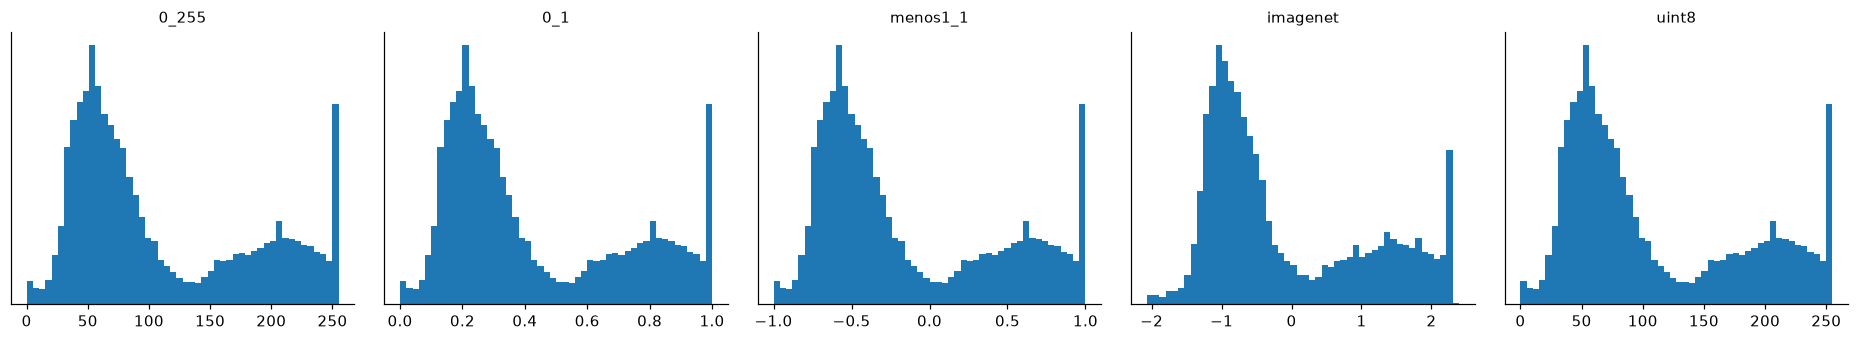

,dtype,min,max,média,desvio
modo,,,,,
0_255,float32,0.000,255.000,110.176,73.371
0_1,float32,0.000,1.000,0.432,0.288
menos1_1,float32,-1.000,1.000,-0.136,0.575
imagenet,float32,-2.067,2.394,-0.084,1.154
uint8,uint8,0.000,255.000,110.176,73.371


In [8]:
im_n = exemplos["hrf_01_h"]
_, m_full = P.recortar_fov(im_n)
m224 = cv2.resize(m_full.astype(np.uint8), (224, 224), interpolation=cv2.INTER_NEAREST).astype(bool)   # só pixels da retina
linhas = []
fig, axs = plt.subplots(1, len(P.NORMALIZACOES), figsize=(3.4 * len(P.NORMALIZACOES), 3.2))
for ax, modo in zip(axs, P.NORMALIZACOES):
    x = P.preparar_para_inferencia(im_n, 224, "clahe", modo)
    inter = x[0][m224]
    ax.hist(inter.ravel(), bins=50, color="tab:blue"); ax.set_title(modo); ax.set_yticks([])
    linhas.append(dict(modo=modo, dtype=str(x.dtype), min=float(inter.min()), max=float(inter.max()), média=float(inter.mean()), desvio=float(inter.std())))
fig.tight_layout(); plt.show()
pd.DataFrame(linhas).set_index("modo").round(3)

**Se o modelo é totalmente quantizado**, a entrada `int8`/`uint8` segue `q = round(x / scale + zero_point)`, com `scale` e `zero_point` guardados no próprio modelo. Exemplo com os valores típicos de uma entrada [−1, 1] em `int8`:

In [9]:
def quantizar_entrada(x_float, scale, zero_point, dtype=np.int8):
    info = np.iinfo(dtype)
    return np.clip(np.round(x_float / scale + zero_point), info.min, info.max).astype(dtype)

x_f = P.preparar_para_inferencia(im_n, 224, "clahe", "menos1_1")
q = quantizar_entrada(x_f, scale=1 / 127.5, zero_point=0)            # ler de interpreter.get_input_details()[0]["quantization"]
x_rec = (q.astype(np.float32) - 0) * (1 / 127.5)
print(f"int8: {q.dtype}, {q.nbytes/1e3:.0f} KB (float32: {x_f.nbytes/1e3:.0f} KB) · erro máx. de quantização = {np.abs(x_f - x_rec).max():.4f} (passo = {1/127.5:.4f})")

int8: int8, 151 KB (float32: 602 KB) · erro máx. de quantização = 0.0039 (passo = 0.0078)


## 6. Fluxo completo: qualidade → tensor, com orçamento de tempo

`fluxo.processar_captura` reúne o que construímos: máscara do FOV → **controle de qualidade** → (se aprovada) tensor de entrada. Capturas reprovadas **não seguem** para os modelos; devolvem os motivos.
Rodamos nas 115 imagens **em resolução total** (a situação real do dispositivo) e medimos o tempo de cada etapa. *(≈ 1–2 minutos.)*

Meta do edital: **≤ 3 s por condição** (modelo incluso) e **RAM ≤ 512 MB por inferência** — o pré-processamento deve ocupar só uma pequena parte desse orçamento.

In [10]:
resultados = []
for _, r in man.iterrows():
    im = dados.carregar_rgb(r.arquivo)
    fl = fluxo.processar_captura(im, 224, "clahe", "menos1_1", exigir_qualidade=True)
    resultados.append(dict(id=r.id, fonte=r.fonte, condicao=r.condicao, mp=im.shape[0] * im.shape[1] / 1e6, aprovada=fl.aprovada,
                           motivos="; ".join(fl.qualidade.motivos), **{f"ms_{k}": v for k, v in fl.tempos_ms.items()}))
res = pd.DataFrame(resultados)
print(f"aprovadas: {res.aprovada.sum()} de {len(res)} ({100*res.aprovada.mean():.1f}%)")
res.groupby("fonte").agg(imagens=("id", "count"), aprovadas_pct=("aprovada", lambda s: 100 * s.mean()), megapixels=("mp", "median"),
                         ms_fov=("ms_fov", "median"), ms_qualidade=("ms_qualidade", "median"), ms_total=("ms_total", "median")).round(1)

aprovadas: 103 de 115 (89.6%)


,imagens,aprovadas_pct,megapixels,ms_fov,ms_qualidade,ms_total
fonte,,,,,,
HRF,45,100.0,8.2,21.2,264.3,418.6
ODIR,42,73.8,0.3,9.6,69.2,83.9
RFMiD,28,96.4,3.1,12.4,124.1,174.2


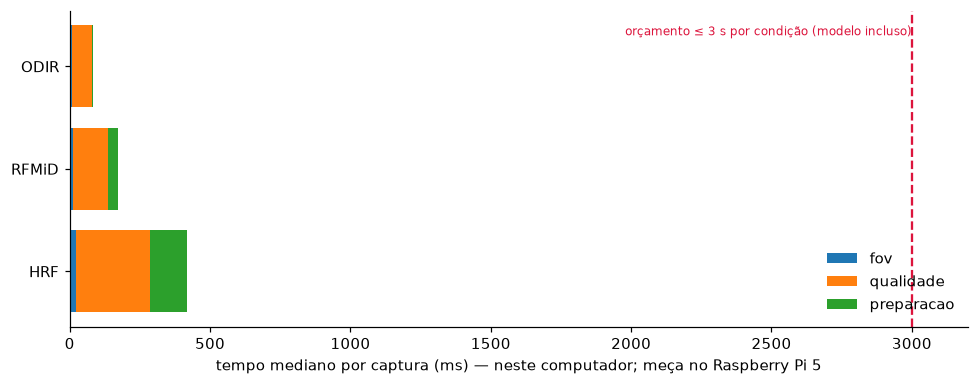

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ordem = ["HRF", "RFMiD", "ODIR"]
bottom = np.zeros(len(ordem))
for etapa, cor in [("ms_fov", "tab:blue"), ("ms_qualidade", "tab:orange"), ("ms_preparacao", "tab:green")]:
    vals = np.array([res[(res.fonte == f) & res.aprovada][etapa].median() for f in ordem])
    ax.barh(ordem, vals, left=bottom, color=cor, label=etapa.replace("ms_", "")); bottom += vals
ax.axvline(3000, color="crimson", ls="--"); ax.text(3000, 2.4, "  orçamento ≤ 3 s por condição (modelo incluso)", color="crimson", fontsize=8, va="top", ha="right")
ax.set_xlabel("tempo mediano por captura (ms) — neste computador; meça no Raspberry Pi 5"); ax.legend(frameon=False, loc="lower right"); ax.set_xlim(0, 3200)
fig.tight_layout(); V.salvar_figura(fig, "06_orcamento_de_tempo"); plt.show()

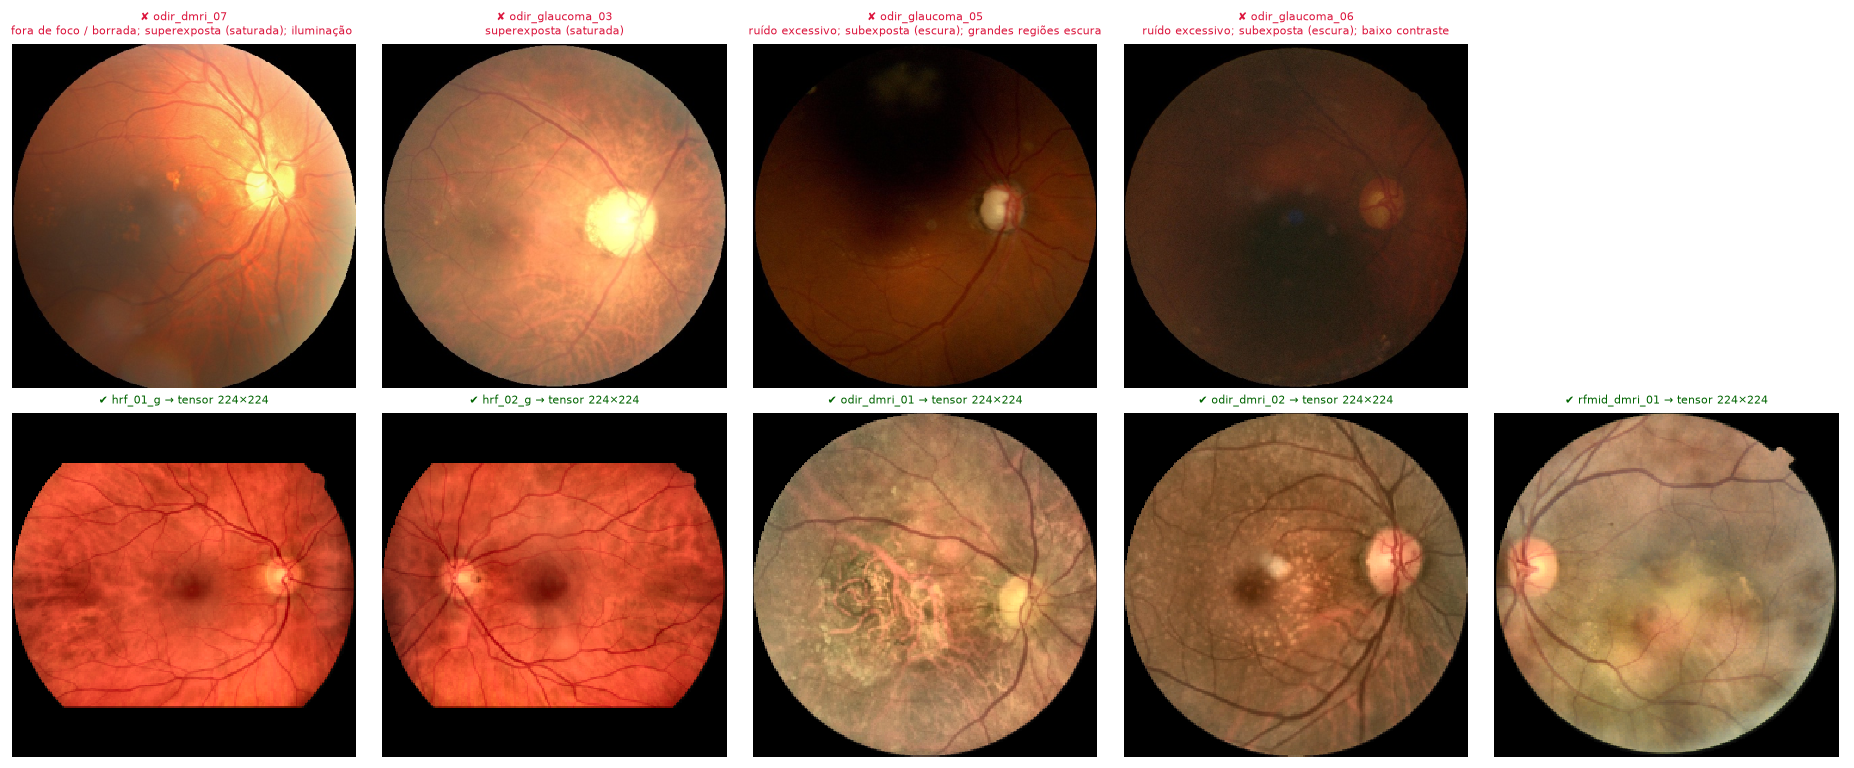

In [12]:
# Capturas reprovadas: motivos e mensagens ao operador; e exemplos de tensores das aprovadas
rej = res[~res.aprovada].head(4); ap = res[res.aprovada].groupby("fonte").head(2).head(6)
fig, axs = plt.subplots(2, 5, figsize=(17, 7))
for a in axs.ravel(): a.axis("off")
for ax, (_, r) in zip(axs[0], rej.iterrows()):
    ax.imshow(dados.reduzir(dados.carregar_rgb(man.set_index("id").loc[r.id, "arquivo"]), 400)); ax.set_title(f"✘ {r.id}\n{r.motivos[:60]}", fontsize=7, color="crimson")
for ax, (_, r) in zip(axs[1], ap.iterrows()):
    x = P.preparar_para_inferencia(dados.carregar_rgb(man.set_index("id").loc[r.id, "arquivo"]), 224, "clahe", "uint8")[0]
    ax.imshow(x); ax.set_title(f"✔ {r.id} → tensor 224×224", fontsize=7, color="darkgreen")
fig.tight_layout(); plt.show()

No HRF (8 MP) a **avaliação de qualidade** responde por ≈ 60 % do tempo mediano e a **preparação** (recorte + redimensionamento + CLAHE) por ≈ 30 %; o cálculo do FOV é barato (≈ 5 %) porque roda numa versão reduzida. Ambos os passos pesados percorrem a imagem em **resolução total**.
Uma otimização óbvia para o Pi: **reduzir a captura uma única vez** para ~ 1024 px e reaproveitar essa cópia na qualidade e no tensor (o notebook 05 mostrou que 1024 px basta para as métricas, desde que os limiares sejam calibrados com essa mesma entrada).

## 7. Paridade treino × inferência: por que "quase igual" não basta

Um modelo aprende com o pré-processamento **do treino**. Se a inferência redimensionar com outra biblioteca ou outro método, o tensor muda um pouco — e o desempenho também.
Comparamos a redução com **OpenCV `INTER_AREA`** (este pipeline) e com **Pillow `BILINEAR`** (padrão de muitos *notebooks* de treino) para a mesma imagem:

In [13]:
rec_, _ = P.recortar_fov(exemplos["rfmid_dmri_03"], quadrado=True)
a = cv2.resize(rec_, (224, 224), interpolation=cv2.INTER_AREA)
b = np.array(Image.fromarray(rec_).resize((224, 224), Image.BILINEAR))
c = np.array(Image.fromarray(rec_).resize((224, 224), Image.LANCZOS))
def em_menos1_1(x): return x.astype(np.float32) / 127.5 - 1
linhas = []
for nome, (x, y) in {"cv2 AREA × Pillow BILINEAR": (a, b), "cv2 AREA × Pillow LANCZOS": (a, c)}.items():
    d = np.abs(em_menos1_1(x) - em_menos1_1(y))
    linhas.append({"comparação": nome, "diferença média (escala [-1,1])": d.mean(), "p99": np.percentile(d, 99), "máx": d.max(), "pixels com Δ > 0,1 (%)": 100 * (d > 0.1).mean()})
pd.DataFrame(linhas).set_index("comparação").round(4)

,"diferença média (escala [-1,1])",p99,máx,"pixels com Δ > 0,1 (%)"
comparação,,,,
cv2 AREA × Pillow BILINEAR,0.0023,0.0392,0.1098,0.0020
cv2 AREA × Pillow LANCZOS,0.0024,0.0314,0.1020,0.0007


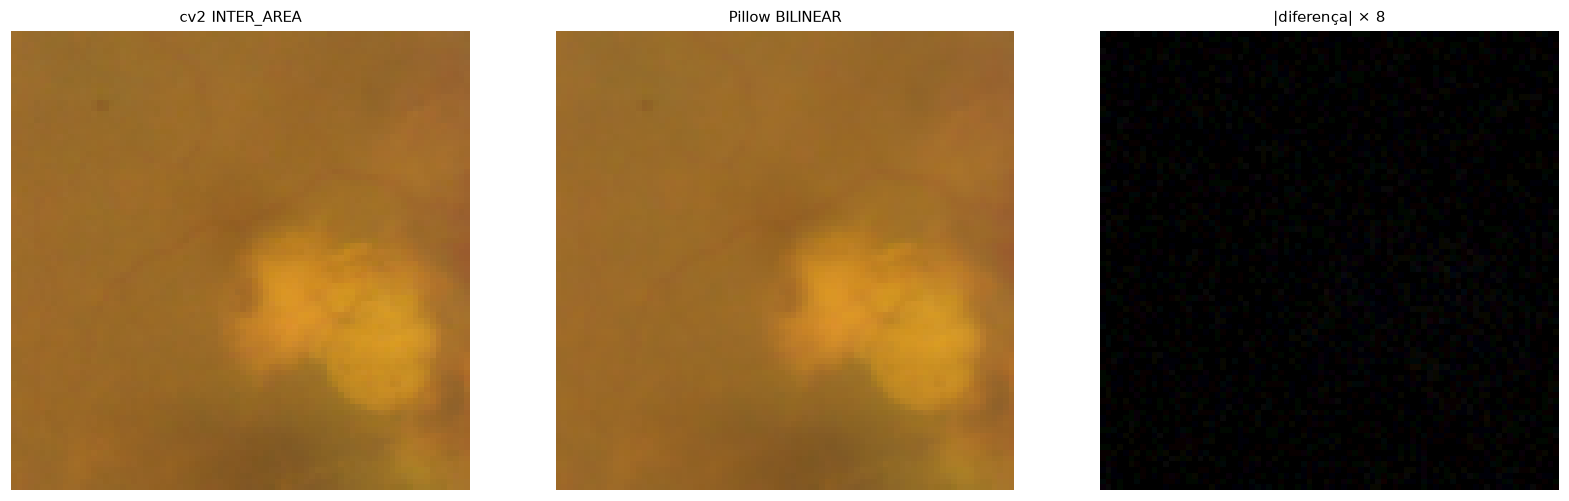

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
zoom_ = (slice(60, 140), slice(60, 140))
for ax, (t_, x) in zip(axs, [("cv2 INTER_AREA", a), ("Pillow BILINEAR", b), ("|diferença| × 8", np.clip(np.abs(a.astype(int) - b.astype(int)) * 8, 0, 255).astype(np.uint8))]):
    ax.imshow(x[zoom_]); ax.set_title(t_); ax.axis("off")
fig.tight_layout(); plt.show()

A diferença média é minúscula (≈ 0,002 na escala [−1, 1], menos de 1 nível de cinza) e **invisível a olho nu**, mesmo ampliada 8× — mas há pixels que diferem em até ≈ 0,1 (≈ 14 níveis).
Invisível não significa irrelevante: se o modelo é sensível a isso, só se descobre **testando** com o modelo real (exercício 3). O caminho seguro é não deixar a diferença existir. **Regras de ouro:**

1. **Congele** o pré-processamento em um único módulo (`retina_pdi.pipeline.preparar_para_inferencia`) e use-o **também no treino** (Frente F3);
2. registre a configuração num arquivo (`config_preprocessamento.json`, abaixo) e **versione-a junto com o modelo**;
3. escreva um **teste de paridade**: o tensor de uma imagem de referência gerado no PC de treino deve ser igual, dentro de uma tolerância, ao gerado no Raspberry Pi.

## 8. Exportando amostras e a configuração

In [15]:
saida = dados.PROCESSADOS
saida.mkdir(parents=True, exist_ok=True)
CONFIG = dict(tamanho=224, realce="clahe", normalizacao="menos1_1", recortar_fov=True, interpolacao="INTER_AREA (reduzir) / INTER_CUBIC (ampliar)",
              clahe=dict(espaco="LAB-L", clip=2.0, grade=[8, 8]), ordem_canais="RGB", formato="NHWC", biblioteca=f"opencv {cv2.__version__}",
              limiares_qualidade=Q.LIMIARES_PADRAO.__dict__)
(saida / "config_preprocessamento.json").write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False), encoding="utf-8")

aprov = res[res.aprovada]
lote, linhas = [], []
for _, r in aprov.iterrows():
    x = P.preparar_para_inferencia(dados.carregar_rgb(man.set_index("id").loc[r.id, "arquivo"]), 224, "clahe", "uint8")[0]
    lote.append(x); linhas.append(dict(indice=len(lote) - 1, id=r.id, fonte=r.fonte, condicao=r.condicao))
lote = np.stack(lote)
np.save(saida / "amostras_224_uint8.npy", lote)
pd.DataFrame(linhas).to_csv(saida / "amostras_224_indice.csv", index=False)
print(f"{lote.shape} {lote.dtype} → {lote.nbytes/1e6:.1f} MB em {saida.relative_to(dados.RAIZ)}")
print(json.dumps({k: CONFIG[k] for k in ["tamanho", "realce", "normalizacao", "recortar_fov"]}))

(103, 224, 224, 3) uint8 → 15.5 MB em data\processed
{"tamanho": 224, "realce": "clahe", "normalizacao": "menos1_1", "recortar_fov": true}


### Do tensor ao modelo (Módulo 4)
Trecho de referência — **não executado aqui** (requer `tflite_runtime`/TensorFlow e um `.tflite` treinado pela Frente F3). Note como a entrada segue exatamente o `get_input_details()`:

```python
import numpy as np
from tflite_runtime.interpreter import Interpreter
from retina_pdi import fluxo

interp = Interpreter(model_path="modelo_rd_int8.tflite", num_threads=4)
interp.allocate_tensors()
entrada = interp.get_input_details()[0]        # shape, dtype, quantization=(scale, zero_point)

resultado = fluxo.processar_captura(rgb, tamanho=entrada["shape"][1], realce="clahe", normalizacao="menos1_1")
if not resultado.aprovada:
    print(resultado.qualidade.motivos)         # pedir nova captura ao operador
else:
    x = resultado.tensor
    if entrada["dtype"] != np.float32:         # modelo quantizado: q = round(x / scale + zero_point)
        scale, zp = entrada["quantization"]
        x = np.clip(np.round(x / scale + zp), np.iinfo(entrada["dtype"]).min, np.iinfo(entrada["dtype"]).max).astype(entrada["dtype"])
    interp.set_tensor(entrada["index"], x)
    interp.invoke()
    saida = interp.get_tensor(interp.get_output_details()[0]["index"])
```

## Exercícios propostos

1. **Orçamento no Pi.** Rode `fluxo.processar_captura` no Raspberry Pi 5 com uma imagem de 4608×2592. Quanto tempo cada etapa leva? O que muda se a captura for reduzida para 1024 px *antes* do FOV e da qualidade?
2. **Interpolação × tarefa.** Repita a seção 2 medindo, em vez do *d* dos vasos, o **Dice** da segmentação de vasos (notebook 04) sobre a imagem reduzida e ampliada de volta. `INTER_AREA` continua vencendo?
3. **Paridade.** Escreva um teste (`pytest`) que compara o tensor de uma imagem de referência com um arquivo `.npy` salvo, com tolerância. Em que condições ele falharia (versão da OpenCV? ordem de canais?)
4. **Sem padding.** Redimensione direto (sem recorte quadrado) para 224×224 e meça a razão de aspecto do disco óptico (largura/altura) antes e depois. Quanto a retina é distorcida?
5. **Escolha do realce.** Com as amostras exportadas, treine (Módulo 4) o mesmo modelo simples com `realce=None`, `"clahe"` e `"ben_graham"` e compare o F1 entre **câmeras diferentes** (treino em HRF, teste em RFMiD).
6. **Recorte da mácula.** Além do quadro inteiro, extraia um recorte 224×224 **centrado no disco** (`localizar_disco_optico`). Isso melhora a detecção de glaucoma (escavação) em relação ao quadro reduzido?